# Trực quan hóa nhận diện rác

Notebook chạy quy trình `ImageProcessor → TrashDetector` trên tối đa 10 ảnh được chọn đều theo thứ tự tên trong `data/test_images/`. Ảnh gốc và ảnh sau khi giữ tỷ lệ, thêm viền (letterbox) kèm khung nhận diện (bounding box) được hiển thị cạnh nhau. Ảnh kết quả và bảng thống kê được lưu trong `results/visualizations/`.

Mô hình hiện trả về 5 nhãn (`Glass`, `Metal`, `Paper`, `Plastic`, `Waste`). Notebook giữ nguyên các nhãn này; cần đối chiếu với nhãn chuẩn trước khi kết luận độ chính xác.

In [1]:
from pathlib import Path
import csv
import sys
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
if not (ROOT / "modules").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "modules").is_dir():
    raise FileNotFoundError("Hãy mở notebook từ thư mục gốc của dự án hoặc thư mục con trực tiếp của nó.")

sys.path.insert(0, str(ROOT))
from modules.image_processor import ImageProcessor
from modules.trash_detector import TrashDetector

IMAGE_DIR = ROOT / "data" / "test_images"
MODEL_PATH = ROOT / "models" / "best_model.pt"
OUTPUT_DIR = ROOT / "results" / "visualizations"
TARGET_SIZE = 640
MAX_IMAGES = 10

if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"Không tìm thấy thư mục ảnh: {IMAGE_DIR}")
if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"Không tìm thấy mô hình YOLO: {MODEL_PATH}")

image_paths = sorted(
    path for path in IMAGE_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)
if not image_paths:
    raise FileNotFoundError(f"Không tìm thấy ảnh có định dạng được hỗ trợ trong {IMAGE_DIR}")

sample_count = min(MAX_IMAGES, len(image_paths))
sample_indices = np.linspace(0, len(image_paths) - 1, sample_count, dtype=int)
selected_images = [image_paths[index] for index in sample_indices]
print(f"Tìm thấy {len(image_paths)} ảnh; sẽ nhận diện trên {len(selected_images)} ảnh mẫu được chọn đều.")
print(f"Mô hình: {MODEL_PATH}")

Tìm thấy 3266 ảnh; sẽ nhận diện trên 10 ảnh mẫu được chọn đều.
Mô hình: c:\Users\qhoan\.vscode\Coding\Data Science\Advanced Python\models\best_model.pt


In [2]:
processor = ImageProcessor(target_size=TARGET_SIZE)
detector = TrashDetector(str(MODEL_PATH))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

rows = []
visualizations = []
for image_path in selected_images:
    original = cv2.imread(str(image_path))
    if original is None:
        raise ValueError(f"Không thể đọc ảnh: {image_path}")

    started = time.perf_counter()
    processed = processor.process(original)
    detections = detector.detect(processed)
    elapsed = time.perf_counter() - started

    annotated = processed.copy()
    for detection in detections:
        x1, y1, x2, y2 = np.rint(detection["bbox"]).astype(int)
        x1, x2 = np.clip([x1, x2], 0, TARGET_SIZE - 1)
        y1, y2 = np.clip([y1, y2], 0, TARGET_SIZE - 1)
        label = f"{detection['class_name']} {detection['confidence']:.2f}"
        cv2.rectangle(annotated, (x1, y1), (x2, y2), (40, 220, 40), 2)
        cv2.putText(annotated, label, (x1, max(18, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (40, 220, 40), 1)

    output_path = OUTPUT_DIR / f"annotated_{image_path.stem}.jpg"
    if not cv2.imwrite(str(output_path), annotated):
        raise OSError(f"Không thể lưu ảnh đã vẽ khung nhận diện: {output_path}")

    rows.append({
        "image": image_path.name,
        "object_count": len(detections),
        "classes": "; ".join(item["class_name"] for item in detections),
        "confidences": "; ".join(f"{item['confidence']:.4f}" for item in detections),
        "processing_seconds": f"{elapsed:.4f}",
        "annotated_image": output_path.name,
    })
    visualizations.append((image_path, annotated, len(detections)))

csv_path = OUTPUT_DIR / "detection_summary.csv"
with csv_path.open("w", newline="", encoding="utf-8-sig") as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)

print(f"Đã lưu {len(rows)} ảnh có khung nhận diện vào {OUTPUT_DIR}")
print(f"Đã lưu bảng kết quả vào {csv_path}")
for row in rows:
    print(row)

Đã lưu 10 ảnh có khung nhận diện vào c:\Users\qhoan\.vscode\Coding\Data Science\Advanced Python\results\visualizations
Đã lưu bảng kết quả vào c:\Users\qhoan\.vscode\Coding\Data Science\Advanced Python\results\visualizations\detection_summary.csv
{'image': 'image_0001.jpg', 'object_count': 0, 'classes': '', 'confidences': '', 'processing_seconds': '4.7634', 'annotated_image': 'annotated_image_0001.jpg'}
{'image': 'image_0363.jpg', 'object_count': 1, 'classes': 'Metal', 'confidences': '0.7657', 'processing_seconds': '0.1986', 'annotated_image': 'annotated_image_0363.jpg'}
{'image': 'image_0726.jpg', 'object_count': 2, 'classes': 'Plastic; Plastic', 'confidences': '0.7579; 0.4517', 'processing_seconds': '0.1967', 'annotated_image': 'annotated_image_0726.jpg'}
{'image': 'image_1089.jpg', 'object_count': 1, 'classes': 'Metal', 'confidences': '0.9491', 'processing_seconds': '0.1871', 'annotated_image': 'annotated_image_1089.jpg'}
{'image': 'image_1452.jpg', 'object_count': 1, 'classes': 'Pa

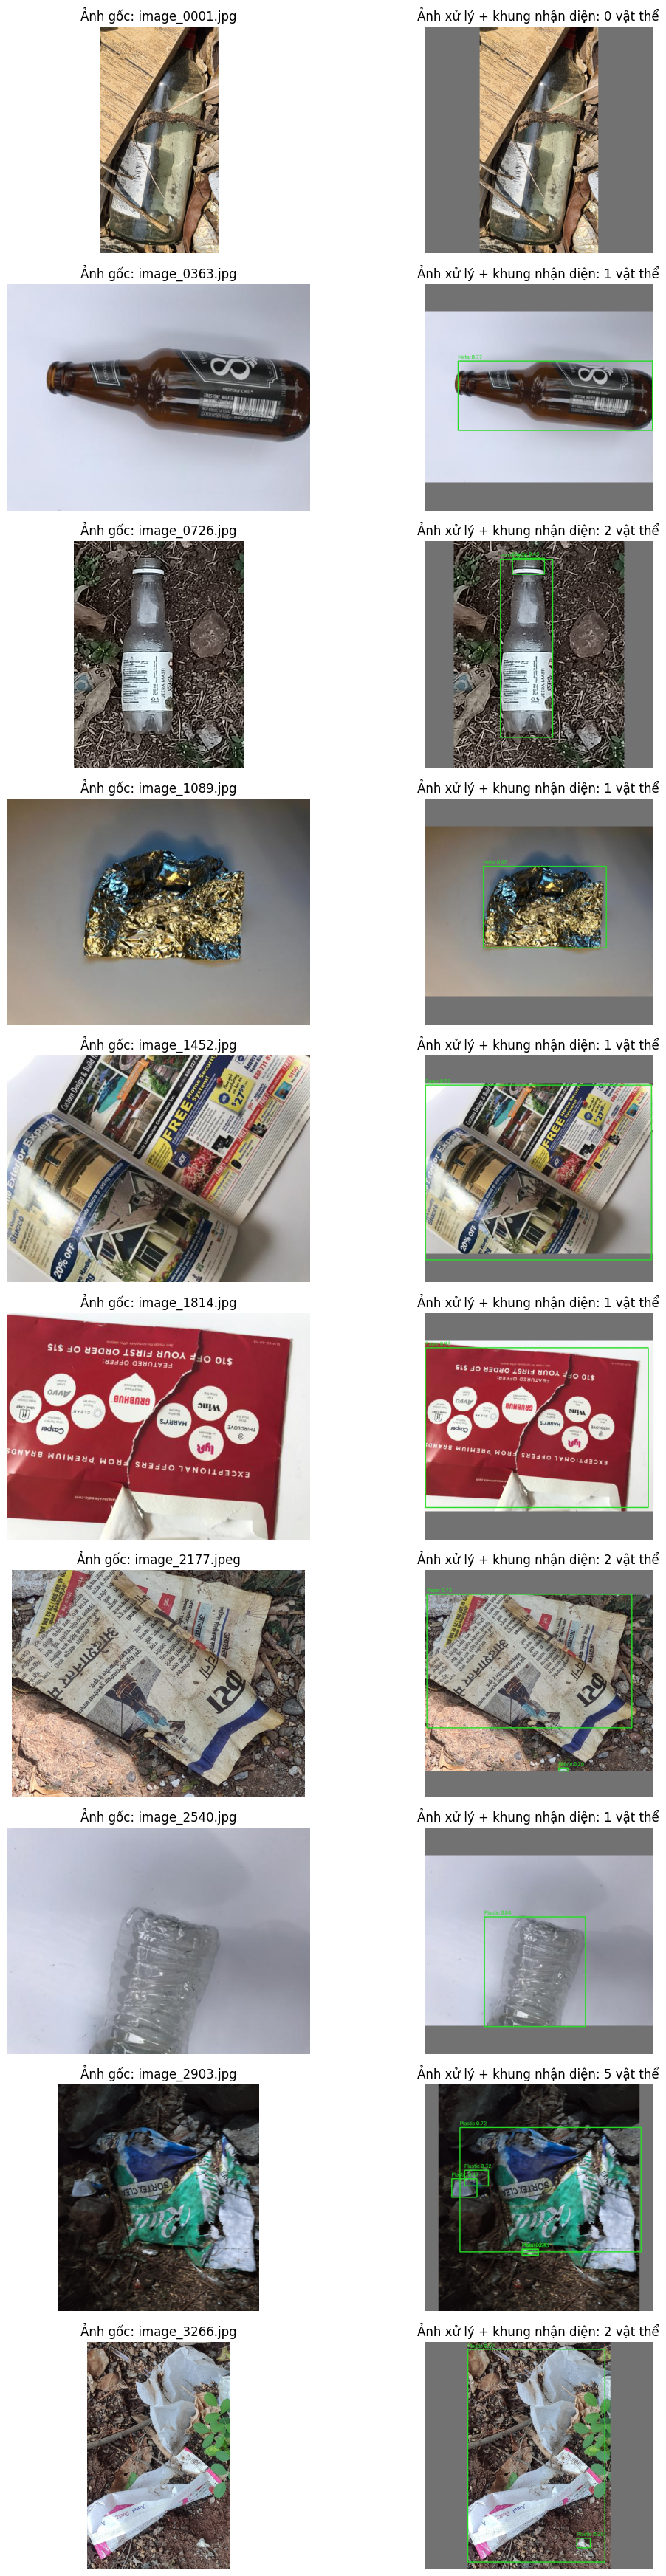

In [3]:
nrows = len(visualizations)
figure, axes = plt.subplots(nrows, 2, figsize=(12, max(4, 3.5 * nrows)), squeeze=False)
for row_index, (image_path, annotated, count) in enumerate(visualizations):
    original = cv2.imread(str(image_path))
    axes[row_index, 0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    axes[row_index, 0].set_title(f"Ảnh gốc: {image_path.name}")
    axes[row_index, 1].imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    axes[row_index, 1].set_title(f"Ảnh xử lý + khung nhận diện: {count} vật thể")
    axes[row_index, 0].axis("off")
    axes[row_index, 1].axis("off")

figure.tight_layout()
figure.savefig(OUTPUT_DIR / "detection_grid.png", dpi=120, bbox_inches="tight")
plt.show()